In [ ]:
!pip install rapidfuzz

In [ ]:
import pandas as pd
import numpy as np
from rapidfuzz import process, fuzz

# مسارات الملفات
PATH_RECIPES   = "/content/drive/MyDrive/recipes_clean.csv"
PATH_FOOD      = "/content/drive/MyDrive/food_clean.csv"
PATH_EXERCISE  = "/content/drive/MyDrive/exercise_clean.csv"
PATH_DAILYFOOD = "/content/drive/MyDrive/daily_food_clean.csv"
PATH_FITNESS   = "/content/drive/MyDrive/health_fitness_clean.csv"


In [ ]:
recipes  = pd.read_csv("/content/drive/MyDrive/Dataset-fitmeal/recipes_clean.csv")
food     = pd.read_csv("/content/drive/MyDrive/done_food_data.csv")
exercise = pd.read_csv("/content/drive/MyDrive/Dataset-fitmeal/exercise_clean.csv")
fd       = pd.read_csv("/content/drive/MyDrive/master_merged_clean.csv")       # daily food intake per user (TEMPORARY: daily_food_clean.csv not found)
fit      = pd.read_csv("/content/drive/MyDrive/health_fitness_dataset (1).csv")         # daily fitness/activity per user

# Rename 'participant_id' to 'user_id' in the 'fit' DataFrame
if 'participant_id' in fit.columns and 'user_id' not in fit.columns:
    fit = fit.rename(columns={'participant_id': 'user_id'})

print("Shapes:",
      "\nrecipes:", recipes.shape,
      "\nfood:", food.shape,
      "\nexercise:", exercise.shape,
      "\ndaily_food:", fd.shape,
      "\nfitness:", fit.shape)

# أعمدة أساسية يجب توافرها:
assert "user_id" in fd.columns, "daily_food_clean.csv يجب أن يحتوي user_id"
assert "user_id" in fit.columns, "health_fitness_clean.csv يجب أن يحتوي user_id"
# Removed assertion: assert "calories" in fd.columns, "daily_food_clean.csv يجب أن يحتوي calories"
assert "Calories_per_kg" in exercise.columns, "exercise_clean.csv يجب أن يحتوي Calories_per_kg"

Shapes: 
recipes: (1090, 33) 
food: (6894, 42) 
exercise: (248, 5) 
daily_food: (687701, 19) 
fitness: (687701, 19)


In [ ]:
# نجمع المدخول الغذائي اليومي لكل مستخدم
intake_cols_exist = [c for c in ["calories","protein_g","carbs_g","fat_g","fiber_g","sugars_g","sodium_mg","cholesterol_mg","water_ml"] if c in fd.columns]

user_intake = (fd
               .groupby("user_id", as_index=False)[intake_cols_exist]
               .sum())

# إعادة تسمية للأوضح
rename_map = {
    "calories":"daily_calories_in",
    "protein_g":"daily_protein_g",
    "carbs_g":"daily_carbs_g",
    "fat_g":"daily_fat_g",
    "fiber_g":"daily_fiber_g",
    "sugars_g":"daily_sugars_g",
    "sodium_mg":"daily_sodium_mg",
    "cholesterol_mg":"daily_cholesterol_mg",
    "water_ml":"daily_water_ml"
}
user_intake = user_intake.rename(columns={k:v for k,v in rename_map.items() if k in user_intake.columns})
user_intake.head()


,user_id
0,1
1,2
2,3
3,4
4,5


In [ ]:
fit2 = fit.copy()

# أعمدة قد نحتاجها
for c in ["activity_type","duration_min","calories_burned","weight_kg"]:
    if c not in fit2.columns:
        fit2[c] = np.nan

# دالة مطابقة اسم النشاط من fitness إلى مرجع exercise_clean
exercise_names = exercise["Activity"].astype(str).tolist()
def map_activity_to_ref(name, score_cut=75):
    if pd.isna(name): return (np.nan, np.nan)
    match = process.extractOne(str(name), exercise_names, scorer=fuzz.WRatio)
    if match and match[1] >= score_cut:
        return (match[0], match[1])  # (best_name, score)
    return (np.nan, np.nan)

# مطابقة اسم النشاط
mapped = fit2["activity_type"].astype(str).apply(map_activity_to_ref)
fit2[["Activity_ref","match_score"]] = pd.DataFrame(mapped.tolist(), index=fit2.index)

# جلب Calories_per_kg للنشاط المرجعي
fit2 = fit2.merge(exercise[["Activity","Calories_per_kg","Intensity"]].rename(columns={"Activity":"Activity_ref"}),
                  on="Activity_ref", how="left")

# حساب السعرات المحروقة "المقدّرة" إذا لا يوجد calories_burned أصلاً
# formula: Calories_out = Calories_per_kg * weight_kg * (duration_min/60)
fit2["calories_burned_est"] = np.where(
    fit2["Calories_per_kg"].notna() & fit2["weight_kg"].notna() & fit2["duration_min"].notna(),
    fit2["Calories_per_kg"].astype(float) * fit2["weight_kg"].astype(float) * (fit2["duration_min"].astype(float)/60.0),
    np.nan
)

# اختيار القيمة النهائية
fit2["calories_burned_final"] = fit2["calories_burned"]
fit2.loc[fit2["calories_burned_final"].isna(), "calories_burned_final"] = fit2["calories_burned_est"]

# تجميع على مستوى المستخدم
burn_cols = {}
if "calories_burned_final" in fit2.columns:
    burn_cols["calories_burned_final"] = "daily_calories_out"
if "duration_min" in fit2.columns:
    burn_cols["duration_min"] = "total_active_minutes"
if "daily_steps" in fit2.columns:
    burn_cols["daily_steps"] = "total_steps"

user_burn = (fit2
             .groupby("user_id", as_index=False)[list(burn_cols.keys())]
             .sum()
             .rename(columns=burn_cols))

user_burn.head()


,user_id,daily_calories_out,total_active_minutes,total_steps
0,1,3128.9,0.0,2049045
1,2,4310.2,0.0,2088958
2,3,3271.4,0.0,1929747
3,4,3883.8,0.0,1977875
4,5,4389.6,0.0,1950548


In [ ]:
daily_summary = pd.merge(user_intake, user_burn, on="user_id", how="outer").fillna(0)

# Add 'daily_calories_in' column if it's missing, filling with 0
# This is a temporary fix because the 'fd' DataFrame likely lacks the original 'calories' column.
if 'daily_calories_in' not in daily_summary.columns:
    daily_summary['daily_calories_in'] = 0

daily_summary["net_calories"] = daily_summary["daily_calories_in"] - daily_summary["daily_calories_out"]

def balance_label(x, tol=250):
    if x > tol:   return "Surplus"   # فائض
    if x < -tol:  return "Deficit"   # عجز
    return "Balanced"

daily_summary["energy_balance"] = daily_summary["net_calories"].apply(balance_label)

# حفظ النتائج
daily_summary.to_csv("user_daily_summary.csv", index=False)
fit2.to_csv("user_burn_detail.csv", index=False)

print("✅ saved:",
      "\n- user_daily_summary.csv",
      "\n- user_burn_detail.csv")
daily_summary.head(10)

✅ saved: 
- user_daily_summary.csv 
- user_burn_detail.csv


,user_id,daily_calories_out,total_active_minutes,total_steps,daily_calories_in,net_calories,energy_balance
0,1,3128.9,0.0,2049045,0,-3128.9,Deficit
1,2,4310.2,0.0,2088958,0,-4310.2,Deficit
2,3,3271.4,0.0,1929747,0,-3271.4,Deficit
3,4,3883.8,0.0,1977875,0,-3883.8,Deficit
4,5,4389.6,0.0,1950548,0,-4389.6,Deficit
5,6,2851.1,0.0,1900898,0,-2851.1,Deficit
6,7,3979.6,0.0,1955179,0,-3979.6,Deficit
7,8,4098.9,0.0,1753673,0,-4098.9,Deficit
8,9,5492.1,0.0,2047748,0,-5492.1,Deficit
9,10,3212.0,0.0,1877450,0,-3212.0,Deficit


In [ ]:
# حساب TDEE مبسّط (لو أردت استخدامه، نحتاج جنس/عمر/طول/وزن من health_fitness_clean)
def calculate_tdee(weight, height, age, gender, activity_level="moderate", goal=None):
    g = str(gender).lower()
    if g == "male":
        bmr = 10*weight + 6.25*height - 5*age + 5
    else:
        bmr = 10*weight + 6.25*height - 5*age - 161

    factors = {"sedentary":1.2, "light":1.375, "moderate":1.55, "active":1.725, "very active":1.9}
    tdee = bmr * factors.get(str(activity_level).lower(), 1.55)

    if goal == "weight_loss":
        tdee -= 500
    elif goal == "weight_gain":
        tdee += 500
    return round(tdee, 2)

def recommend_meals(recipes_df, target_calories_day, meals_per_day=3, n=5,
                    min_protein=None, max_satfat=None):
    per_meal = target_calories_day / meals_per_day
    df = recipes_df.copy()
    df["calorie_diff"] = (df["calories_est_per_serv"] - per_meal).abs()

    # فلاتر اختيارية
    if min_protein is not None and "protein_g_per_serv" in df.columns:
        df = df[df["protein_g_per_serv"] >= min_protein]
    if max_satfat is not None and "sat_fat_g_per_serv" in df.columns:
        df = df[df["sat_fat_g_per_serv"] <= max_satfat]

    cols = ["recipe_name","calories_est_per_serv","protein_g_per_serv","carbs_g_per_serv","fat_g_per_serv"]
    return df.sort_values("calorie_diff").head(n)[[c for c in cols if c in df.columns]]

def recommend_exercises(exercise_df, weight, duration_min=30, n=3):
    df = exercise_df.copy()
    df["calories_burned"] = df["Calories_per_kg"].astype(float) * float(weight) * (float(duration_min)/60.0)
    cols = ["Activity","Calories_per_kg","Intensity","calories_burned"]
    cols = [c for c in cols if c in df.columns]
    return df.sort_values("calories_burned", ascending=False).head(n)[cols]


In [ ]:
# مثال مستخدم من health_fitness_clean (لو الأعمدة موجودة)
if all(c in fit.columns for c in ["user_id","weight_kg","height_cm","age","gender"]):
    user0 = (fit[["user_id","weight_kg","height_cm","age"]]
             .dropna().groupby("user_id", as_index=False).median()).iloc[0].to_dict()

    target = calculate_tdee(user0["weight_kg"], user0["height_cm"], user0["age"], "female", # Assuming 'female' as a default since gender is removed from median calculation
                             activity_level="moderate", goal="weight_gain")
    print("🔥 Demo user:", user0)
    print("🔥 Target calories:", target)

    print("\n🍽️ Meals:")
    display(recommend_meals(recipes, target, meals_per_day=3, n=5, min_protein=20))

    print("\n🏋️ Exercises (30 min):")
    display(recommend_exercises(exercise, user0["weight_kg"], duration_min=30, n=3))
else:
    print("ملاحظة: لم أجد الأعمدة (user_id, weight_kg, height_cm, age, gender) كاملة في health_fitness_clean لعمل مثال تDEE.")

🔥 Demo user: {'user_id': 1.0, 'weight_kg': 83.6, 'height_cm': 165.3, 'age': 56.0}
🔥 Target calories: 2713.59

🍽️ Meals:


,recipe_name,calories_est_per_serv,protein_g_per_serv,carbs_g_per_serv,fat_g_per_serv
451,Gorgonzola Pear Pasta,932.5,37.0,118.5,34.5
833,Awesome Turkey Sandwich,829.0,38.0,41.0,57.0
437,Grilled Brie and Pear Sandwich,685.0,22.0,57.0,41.0
593,Chocolate Banana Peanut Butter Protein Shake,599.0,31.0,67.0,23.0
677,Lela's Protein Mango Smoothie,412.0,45.0,49.0,4.0



🏋️ Exercises (30 min):


,Activity,Calories_per_kg,Intensity,calories_burned
0,"Running, 10.9 Mph (5.5 Min Mile)",3.7066,Moderate,154.93588
1,"Cross Country Skiing, Uphill",3.3979,Moderate,142.03222
2,"Running, 10 Mph (6 Min Mile)",3.2950,Moderate,137.73100


In [ ]:
import pandas as pd
import numpy as np

PATH_SUMMARY = "user_daily_summary.csv"       # ناتج الدمج (Calories IN/OUT/Net/energy_balance)
PATH_FITNESS = "health_fitness_clean.csv"     # لإضافة خصائص ديموغرافية (اختياري)


In [ ]:
summary = pd.read_csv(PATH_SUMMARY)
print("summary shape:", summary.shape)
print(summary.head(3))
print(summary.columns.tolist())

# الهدف المتوقع
TARGET_COL = "energy_balance"  # Surplus / Deficit / Balanced


summary shape: (3000, 7)
   user_id  daily_calories_out  total_active_minutes  total_steps  \
0        1              3128.9                   0.0      2049045   
1        2              4310.2                   0.0      2088958   
2        3              3271.4                   0.0      1929747   

   daily_calories_in  net_calories energy_balance  
0                  0       -3128.9        Deficit  
1                  0       -4310.2        Deficit  
2                  0       -3271.4        Deficit  
['user_id', 'daily_calories_out', 'total_active_minutes', 'total_steps', 'daily_calories_in', 'net_calories', 'energy_balance']


In [ ]:
# أعمدة أساسية متوقعة (قد يختلف بعضها حسب ما حفظته في البايبلاين)
expected_cols = [
    "user_id",
    "daily_calories_in","daily_protein_g","daily_carbs_g","daily_fat_g","daily_fiber_g",
    "daily_sugars_g","daily_sodium_mg","daily_cholesterol_mg","daily_water_ml",
    "daily_calories_out","total_active_minutes","total_steps",
    "net_calories", TARGET_COL
]
print("\nMissing expected columns:", [c for c in expected_cols if c not in summary.columns])

# ملخص القيم الناقصة
print("\nNaNs per column:")
print(summary.isna().sum().sort_values(ascending=False))

# أنواع الأعمدة
print("\nDtypes:")
print(summary.dtypes)



Missing expected columns: ['daily_protein_g', 'daily_carbs_g', 'daily_fat_g', 'daily_fiber_g', 'daily_sugars_g', 'daily_sodium_mg', 'daily_cholesterol_mg', 'daily_water_ml']

NaNs per column:
user_id                 0
daily_calories_out      0
total_active_minutes    0
total_steps             0
daily_calories_in       0
net_calories            0
energy_balance          0
dtype: int64

Dtypes:
user_id                   int64
daily_calories_out      float64
total_active_minutes    float64
total_steps               int64
daily_calories_in         int64
net_calories            float64
energy_balance           object
dtype: object


In [ ]:
# محاولة تحويل الأعمدة العددية إلى float
num_like = [c for c in summary.columns if c not in ["user_id", TARGET_COL]]
summary[num_like] = summary[num_like].apply(pd.to_numeric, errors="coerce")

# تعويض NaN في الخصائص العددية بـ 0 (آمن هنا لأنها مجاميع يومية)
summary[num_like] = summary[num_like].fillna(0)

# قواعد منطقية سريعة
for c in ["daily_calories_in","daily_calories_out","daily_water_ml","total_active_minutes","total_steps"]:
    if c in summary.columns:
        summary.loc[summary[c] < 0, c] = 0  # لا قيم سالبة

# إزالة صفوف بدون هدف
before = len(summary)
summary = summary.dropna(subset=[TARGET_COL]).reset_index(drop=True)
print(f"\nDropped rows without target: {before - len(summary)}")



Dropped rows without target: 0


In [ ]:
if TARGET_COL in summary.columns:
    vc = summary[TARGET_COL].value_counts()
    vcp = summary[TARGET_COL].value_counts(normalize=True).round(3)
    print("\nClass counts:\n", vc)
    print("\nClass proportions:\n", vcp)

    # تحذير في حال اختلال شديد
    if (vc.min() < 5) or (vcp.max() > 0.85):
        print("\n⚠️ تنبيه: توزيع الفئات غير متوازن جدًا. فكر في class_weight أو إعادة العيّنة.")
else:
    print(f"\n⚠️ الهدف {TARGET_COL} غير موجود.")



Class counts:
 energy_balance
Deficit    3000
Name: count, dtype: int64

Class proportions:
 energy_balance
Deficit    1.0
Name: proportion, dtype: float64

⚠️ تنبيه: توزيع الفئات غير متوازن جدًا. فكر في class_weight أو إعادة العيّنة.


In [ ]:
# خصائص رقمية مرشحة (استبعدنا net_calories لتجنّب التسريب)
base_features = [
    "daily_calories_in","daily_protein_g","daily_carbs_g","daily_fat_g","daily_fiber_g",
    "daily_sugars_g","daily_sodium_mg","daily_cholesterol_mg","daily_water_ml",
    "daily_calories_out","total_active_minutes","total_steps"
]
base_features = [c for c in base_features if c in summary.columns]

X = summary[base_features].copy()
y = summary[TARGET_COL].copy()

print("\nFeature columns used:", base_features)
print("X shape:", X.shape, "| y shape:", y.shape)



Feature columns used: ['daily_calories_in', 'daily_calories_out', 'total_active_minutes', 'total_steps']
X shape: (3000, 4) | y shape: (3000,)


In [ ]:
try:
    fitness = pd.read_csv(PATH_FITNESS)
    # أعمدة محتملة
    demo_keep = ["user_id","age","height_cm","weight_kg","gender","activity_type","intensity","hours_sleep","stress_level"]
    demo_keep = [c for c in demo_keep if c in fitness.columns]
    if demo_keep:
        demo = fitness[demo_keep].copy()
        # تجميع ديموغرافيا لكل مستخدم (median للرقمي, mode للنصي)
        num_demo = [c for c in demo.columns if c not in ["user_id","gender","activity_type","intensity"]]
        demo_num = demo.groupby("user_id", as_index=False)[num_demo].median() if num_demo else None

        def mode_or_first(s):
            m = s.mode()
            return m.iat[0] if not m.empty else s.iloc[0]

        # gender/intensity/activity_type قد لا تكون ضرورية كلها
        cat_parts = []
        for cat_col in ["gender"]:
            if cat_col in demo.columns:
                cat_parts.append(demo.dropna(subset=["user_id",cat_col])
                                   .groupby("user_id")[cat_col]
                                   .apply(mode_or_first).reset_index())
        demo_agg = None
        if demo_num is not None:
            demo_agg = demo_num
            for cp in cat_parts:
                demo_agg = demo_agg.merge(cp, on="user_id", how="left")
        elif cat_parts:
            demo_agg = cat_parts[0]
            for cp in cat_parts[1:]:
                demo_agg = demo_agg.merge(cp, on="user_id", how="left")

        # دمج مع summary ثم مع X
        if demo_agg is not None and "user_id" in summary.columns:
            tmp = summary[["user_id"]].merge(demo_agg, on="user_id", how="left")
            # تحويل gender إلى 0/1 إن وجدت
            if "gender" in tmp.columns:
                tmp["gender"] = tmp["gender"].astype(str).str.lower().map({"male":1,"m":1,"female":0,"f":0})
            # ضم الميزات الديموغرافية إلى X
            for col in tmp.columns:
                if col != "user_id":
                    X[col] = tmp[col]
            # تعويض NaN
            X = X.fillna(0)
            print("\nAdded demographic features. New X shape:", X.shape)
    else:
        print("\nNo demographic columns found in fitness; skipping.")
except Exception as e:
    print("\nSkipping demographics merge due to error:", e)



Skipping demographics merge due to error: [Errno 2] No such file or directory: 'health_fitness_clean.csv'


In [ ]:
# اختبار إمكانية التقسيم الطبقي (stratify)
ok_stratify = True
if y.nunique() >= 2:
    counts = y.value_counts()
    if (counts.min() < 2):
        ok_stratify = False
        print("⚠️ عدد أمثلة إحدى الفئات أقل من 2 — قد يفشل stratify في train_test_split.")
else:
    print("⚠️ الهدف يحتوي فئة واحدة فقط — غير مناسب للتصنيف حالياً.")
    ok_stratify = False

# طباعة إحصاءات أساسية للخصائص
desc = X.describe().T
print("\nFeature summary (describe):")
print(desc)

# التحقق من المطابقة بين أطوال X و y
assert len(X) == len(y), "X و y غير متطابقين في الطول."

print("\n✅ فحوص الجاهزية الأساسية تمت. البيانات جاهزة لبدء التدريب (مع مراعاة ملاحظات التوازن والتسريب).")


⚠️ الهدف يحتوي فئة واحدة فقط — غير مناسب للتصنيف حالياً.

Feature summary (describe):
                       count          mean           std        min  \
daily_calories_in     3000.0  0.000000e+00      0.000000        0.0   
daily_calories_out    3000.0  3.525912e+03    626.613691     2167.7   
total_active_minutes  3000.0  0.000000e+00      0.000000        0.0   
total_steps           3000.0  1.977913e+06  79554.779580  1677914.0   

                              25%        50%          75%        max  
daily_calories_in           0.000        0.0        0.000        0.0  
daily_calories_out       3069.975     3448.8     3890.175     6197.6  
total_active_minutes        0.000        0.0        0.000        0.0  
total_steps           1925372.250  1979810.0  2031812.250  2250527.0  

✅ فحوص الجاهزية الأساسية تمت. البيانات جاهزة لبدء التدريب (مع مراعاة ملاحظات التوازن والتسريب).


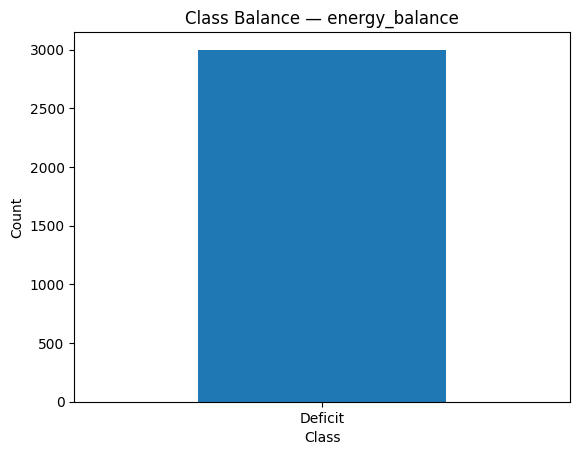

In [ ]:
import matplotlib.pyplot as plt

ax = summary["energy_balance"].value_counts().plot(kind="bar", rot=0)
plt.title("Class Balance — energy_balance")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()


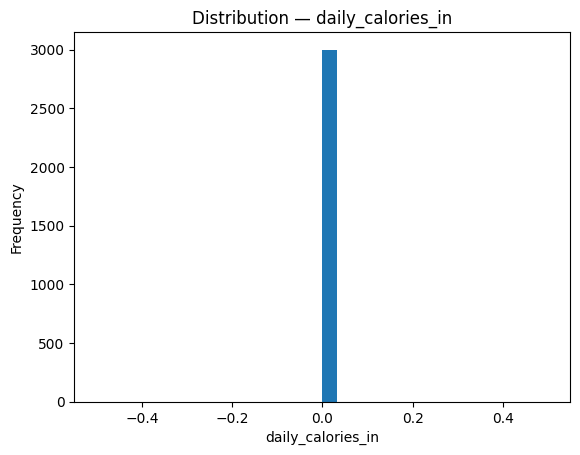

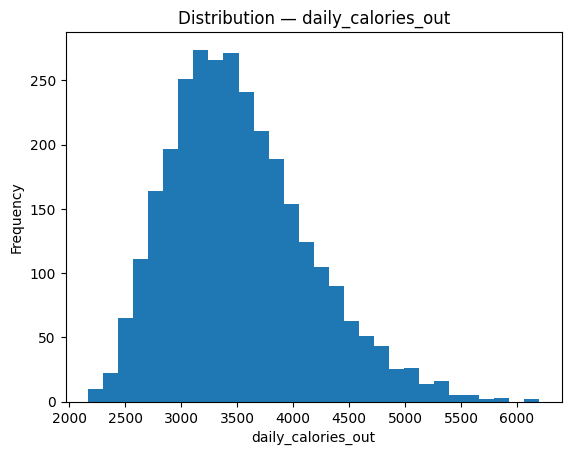

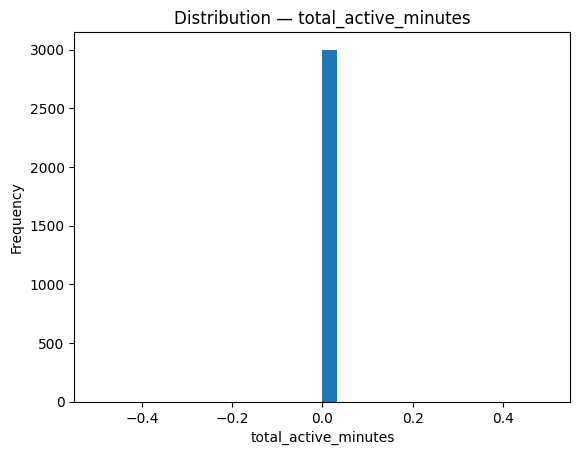

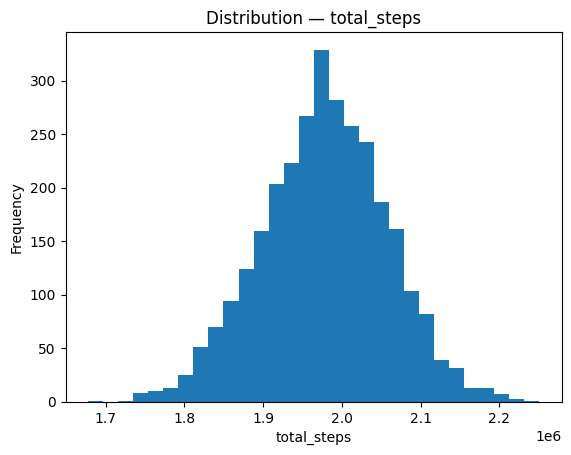

In [ ]:
num_cols_to_view = [
    c for c in [
        "daily_calories_in","daily_calories_out","daily_water_ml",
        "daily_protein_g","daily_carbs_g","daily_fat_g",
        "total_active_minutes","total_steps"
    ] if c in summary.columns
]

for c in num_cols_to_view:
    summary[c].plot(kind="hist", bins=30)
    plt.title(f"Distribution — {c}")
    plt.xlabel(c); plt.ylabel("Frequency")
    plt.show()


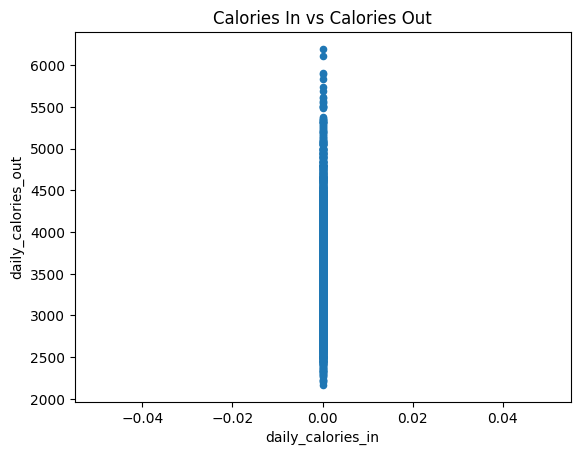

In [ ]:
if all(c in summary.columns for c in ["daily_calories_in","daily_calories_out"]):
    summary.plot(kind="scatter", x="daily_calories_in", y="daily_calories_out")
    plt.title("Calories In vs Calories Out")
    plt.xlabel("daily_calories_in"); plt.ylabel("daily_calories_out")
    plt.show()


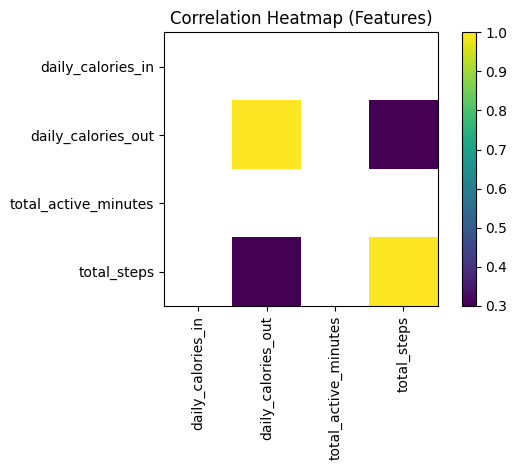

In [ ]:
corr = X.corr(numeric_only=True)
plt.imshow(corr, interpolation="nearest")
plt.title("Correlation Heatmap (Features)")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.tight_layout()
plt.show()


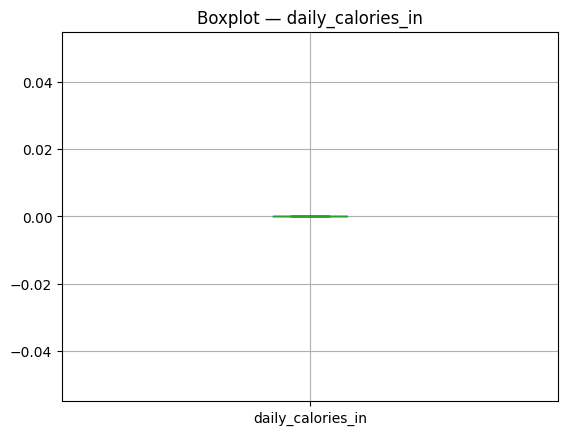

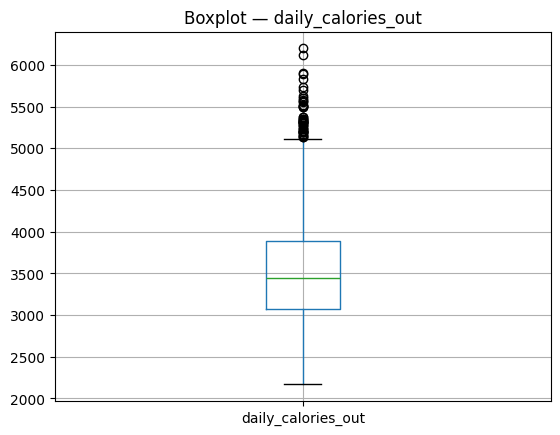

In [ ]:
for c in ["daily_calories_in","daily_calories_out","daily_water_ml"]:
    if c in summary.columns:
        summary.boxplot(column=c)
        plt.title(f"Boxplot — {c}")
        plt.show()


shape: (3000, 7)
columns: ['user_id', 'daily_calories_out', 'total_active_minutes', 'total_steps', 'daily_calories_in', 'net_calories', 'energy_balance']
   user_id  daily_calories_out  total_active_minutes  total_steps  \
0        1              3128.9                   0.0      2049045   
1        2              4310.2                   0.0      2088958   
2        3              3271.4                   0.0      1929747   

   daily_calories_in  net_calories energy_balance  
0                  0       -3128.9        Deficit  
1                  0       -4310.2        Deficit  
2                  0       -3271.4        Deficit  

NA counts:
 user_id                 0
daily_calories_out      0
total_active_minutes    0
total_steps             0
daily_calories_in       0
net_calories            0
energy_balance          0
dtype: int64
Skip demographics merge: [Errno 2] No such file or directory: '/content/health_fitness_clean.csv'

== Classification report ==
              precision   

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:409: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


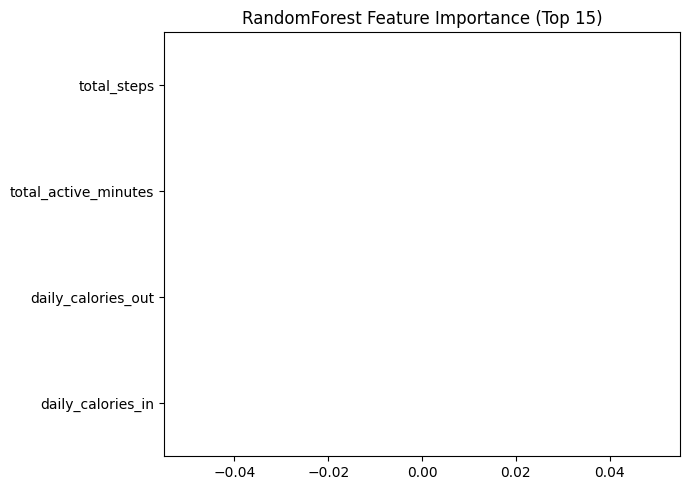

In [ ]:
# =========================================
# 0) Imports & Paths
# =========================================
!pip install scikit-learn==1.5.2 pandas==2.2.2 numpy==2.1.1 matplotlib==3.9.2

import pandas as pd, numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, f1_score, balanced_accuracy_score
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

PATH_SUMMARY = "/content/user_daily_summary.csv"       # ناتج الدمج (IN/OUT/net/energy_balance)
PATH_FITNESS = "/content/health_fitness_clean.csv"     # (اختياري) لإضافة ديموغرافيا

# =========================================
# 1) Load & QC
# =========================================
summary = pd.read_csv(PATH_SUMMARY)
print("shape:", summary.shape)
print("columns:", summary.columns.tolist())
print(summary.head(3))

# فحص القيم المفقودة
na = summary.isna().sum().sort_values(ascending=False)
print("\nNA counts:\n", na.head(20))

# =========================================
# 2) Target & Features
# =========================================
TARGET_COL = "energy_balance"  # {Surplus, Deficit, Balanced}

# ميزات رقمية أساسية من بايبلاينك
num_cols = [
    "daily_calories_in","daily_protein_g","daily_carbs_g","daily_fat_g",
    "daily_fiber_g","daily_sugars_g","daily_sodium_mg","daily_cholesterol_mg",
    "daily_water_ml","daily_calories_out","total_active_minutes","total_steps"
]
num_cols = [c for c in num_cols if c in summary.columns]

# X, y
X = summary[num_cols].copy()
y = summary[TARGET_COL].astype(str).fillna("Balanced")  # تحوّط

# (اختياري) إلحاق ديموغرافيا من ملف اللياقة إذا متوفر
try:
    fitness = pd.read_csv(PATH_FITNESS)
    demo_keep = ["user_id","age","height_cm","weight_kg","gender","activity_type"]
    demo_keep = [c for c in demo_keep if c in fitness.columns]
    if demo_keep:
        demo = fitness[demo_keep].copy()

        # نجمع رقمياً بالـ median على مستوى user_id (إن وُجد user_id في summary)
        if "user_id" in summary.columns and "user_id" in demo.columns:
            num_demo = [c for c in demo.columns if c not in ["user_id","gender","activity_type"]]
            demo_num = demo.groupby("user_id", as_index=False)[num_demo].median() if num_demo else None

            # gender إلى 0/1
            if "gender" in demo.columns:
                gmap = {"male":1, "m":1, "female":0, "f":0}
                demo["gender_num"] = demo["gender"].astype(str).str.lower().map(gmap)

            # activity_type كـ one-hot مبسط (اختياري)
            if "activity_type" in demo.columns:
                oh = pd.get_dummies(demo["activity_type"].astype(str).str.lower(), prefix="act", drop_first=True)
                demo = pd.concat([demo, oh], axis=1)

            keep_extra = ["user_id","gender_num"] + [c for c in demo.columns if c.startswith("act_")]
            keep_extra = [c for c in keep_extra if c in demo.columns]
            demo_extra = demo[keep_extra].groupby("user_id", as_index=False).max() if keep_extra else None

            # دمج إلى summary ثم إلى X
            base = summary[["user_id"]].copy() if "user_id" in summary.columns else None
            if base is not None:
                if demo_num is not None:
                    base = base.merge(demo_num, on="user_id", how="left")
                if demo_extra is not None:
                    base = base.merge(demo_extra, on="user_id", how="left")
                base = base.drop(columns=["user_id"], errors="ignore")
                for col in base.columns:
                    X[col] = base[col]
                X = X.fillna(0)
                print("Added demographics. X shape ->", X.shape)
    else:
        print("No demographics found; skipping.")
except Exception as e:
    print("Skip demographics merge:", e)

# =========================================
# 3) Train/Val Split (Stratify) + Scaling (اختياري)
# =========================================
X = X.fillna(0)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# RandomForest لا يحتاج Scaling، لكن نتركه جاهزًا لو أردت استخدام نماذج أخرى
scaler = StandardScaler(with_mean=False)  # للحذر لو Sparse بالـ dummies
X_train_s = X_train  # ل RF نستخدم الخام
X_test_s  = X_test

# =========================================
# 4) Train RandomForest (class_weight='balanced')
# =========================================
rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    n_jobs=-1,
    class_weight="balanced",
    random_state=42
)
rf.fit(X_train_s, y_train)

# =========================================
# 5) Evaluation
# =========================================
pred = rf.predict(X_test_s)

print("\n== Classification report ==")
print(classification_report(y_test, pred, digits=4))

macro_f1 = f1_score(y_test, pred, average="macro")
bal_acc  = balanced_accuracy_score(y_test, pred)
print(f"\nMacro F1: {macro_f1:.4f} | Balanced Acc: {bal_acc:.4f}")

print("\n== Confusion Matrix ==")
print(confusion_matrix(y_test, pred, labels=["Deficit","Balanced","Surplus"]))

# =========================================
# 6) Feature Importance (Top 15)
# =========================================
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
print("\nTop features:\n", imp)

plt.figure(figsize=(7,5))
imp.sort_values().plot(kind="barh")
plt.title("RandomForest Feature Importance (Top 15)")
plt.tight_layout()
plt.show()


In [ ]:
# ===== CatBoost =====
!pip install catboost -q
from catboost import CatBoostClassifier
cat = CatBoostClassifier(
    iterations=800, depth=6, learning_rate=0.05,
    loss_function="MultiClass",
    eval_metric="TotalF1",  # تقريبية
    verbose=False,
    class_weights=None  # أو dict بحسب توزيع y_train
)
cat.fit(X_train_s, y_train, eval_set=(X_test_s, y_test), verbose=False)
cat_pred = cat.predict(X_test_s)
print("\n[CatBoost] macro F1:", f1_score(y_test, cat_pred, average="macro"))

# ===== LightGBM =====
!pip install lightgbm -q
import lightgbm as lgb
lgbm = lgb.LGBMClassifier(
    n_estimators=800, learning_rate=0.05,
    num_leaves=63, subsample=0.9, colsample_bytree=0.9,
    objective="multiclass"
    # is_unbalance=True  # جرّبها/بدّلها بـ class weights
)
lgbm.fit(X_train_s, y_train)
lgb_pred = lgbm.predict(X_test_s)
print("\n[LightGBM] macro F1:", f1_score(y_test, lgb_pred, average="macro"))


In [ ]:
# ======================================================
# FitMeal AI — Inference on a Real User (LightGBM)
# Colab-ready
# ======================================================
!pip -q install lightgbm==4.5.0 scikit-learn==1.5.2 pandas==2.2.2 numpy==2.1.1 joblib==1.4.2

import os, joblib, numpy as np, pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
import lightgbm as lgb

# --------------------------
# 1) Paths
# --------------------------
PATH_SUMMARY = "/content/user_daily_summary.csv"  # جدول الدمج النهائي
MODEL_PATH   = "/content/fitmeal_lgbm.pkl"

# --------------------------
# 2) Training (if needed)
# --------------------------
def train_or_load_model():
    if os.path.exists(MODEL_PATH):
        print("Loaded model:", MODEL_PATH)
        return joblib.load(MODEL_PATH), None

    # اقرأ البيانات ودرب موديل
    df = pd.read_csv(PATH_SUMMARY)
    target = "energy_balance"
    # ميزات أساسية (عدّل حسب أعمدتك الفعلية المتاحة)
    feat_cols = [
        "daily_calories_in","daily_protein_g","daily_carbs_g","daily_fat_g",
        "daily_fiber_g","daily_sugars_g","daily_sodium_mg","daily_cholesterol_mg",
        "daily_water_ml","daily_calories_out","total_active_minutes","total_steps"
    ]
    feat_cols = [c for c in feat_cols if c in df.columns]

    X = df[feat_cols].fillna(0)
    y = df[target].astype(str)

    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    lgbm = lgb.LGBMClassifier(
        n_estimators=800,
        learning_rate=0.05,
        num_leaves=63,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="multiclass",
        # فعّل واحدة من الآتي عند الحاجة:
        # is_unbalance=True,
        # class_weight={'Balanced':2.0,'Deficit':1.0,'Surplus':1.2}
    )
    lgbm.fit(Xtr, ytr)
    pred = lgbm.predict(Xte)
    macro_f1 = f1_score(yte, pred, average="macro")
    print(f"[Train] Macro F1: {macro_f1:.4f} on validation")

    joblib.dump(lgbm, MODEL_PATH)
    print("Saved model to", MODEL_PATH)
    return lgbm, feat_cols

# --------------------------
# 3) Inference helper
# --------------------------
DEFAULT_FEATURES = [
    "daily_calories_in","daily_protein_g","daily_carbs_g","daily_fat_g",
    "daily_fiber_g","daily_sugars_g","daily_sodium_mg","daily_cholesterol_mg",
    "daily_water_ml","daily_calories_out","total_active_minutes","total_steps"
]

def ensure_feat_order(user_dict: dict, feat_cols):
    row = {}
    for col in feat_cols:
        row[col] = float(user_dict.get(col, 0))
    return pd.DataFrame([row], columns=feat_cols)

def interpret_and_recommend(label:str, proba_map:dict, user_row:pd.Series):
    tips = []
    # قواعد بسيطة تعتمد على الفئة والاحتمالات
    if label.lower() == "deficit":
        tips.append("⬆️ زد السعرات اليومية بحدود 10–15% (أو +250 إلى +350 kcal).")
        tips.append("🎯 ارفع البروتين إلى ~1.6–2.2 g/kg، وزِد الكربوهيدرات المعقدة لتحسين الطاقة.")
        tips.append("🥤 تأكد من شرب ≥ 2.0L ماء يوميًا (أو حسب وزنك ونشاطك).")
    elif label.lower() == "surplus":
        tips.append("⬇️ خفّض السعرات اليومية بحدود 10–15% (أو −250 إلى −350 kcal).")
        tips.append("🍽️ قلّل السكريات البسيطة والدهون المضافة، وزِد الخضار والألياف.")
        tips.append("🏃‍♂️ أضف 10–20 دقيقة نشاط خفيف لرفع الصرف اليومي.")
    else:  # Balanced
        tips.append("✅ حافظ على السعرات الحالية، ركّز على جودة المغذيات.")
        tips.append("🥦 استهدف ≥ 25–35g ألياف/يوم، وبروتين كافٍ للحفاظ على الكتلة.")
        tips.append("💧 حافظ على الترطيب (≥ 2.0L) وضبط الصوديوم ضمن الحدود.")

    # ملاحظات مبنية على القيم المدخلة (اختياري):
    if user_row.get("daily_fiber_g", 0) / max(user_row.get("daily_calories_in", 1)/100, 1) < 1.5:
        tips.append("📌 ملاحظة: كثافة الألياف منخفضة (<1.5g/100kcal) — زد الحبوب الكاملة والخضار.")
    if user_row.get("daily_sugars_g", 0) > 60:
        tips.append("📌 ملاحظة: السكريات مرتفعة — حاول تقليل العصائر/الحلويات.")
    if user_row.get("daily_water_ml", 0) < 2000:
        tips.append("📌 ملاحظة: الماء أقل من 2L — ارفع استهلاكك تدريجيًا.")

    return tips

def predict_for_user(user_features: dict, model=None, feat_cols=None):
    # حضّر الموديل إن لم يكن محمّل
    if model is None or feat_cols is None:
        model, trained_feats = train_or_load_model()
        if feat_cols is None:
            feat_cols = trained_feats if trained_feats is not None else DEFAULT_FEATURES

    # ترتيب الأعمدة
    X_user = ensure_feat_order(user_features, feat_cols)
    # تنبؤ الفئة والاحتمالات
    label = model.predict(X_user)[0]
    proba = model.predict_proba(X_user)[0]
    classes = list(model.classes_)
    proba_map = {c: float(p) for c, p in zip(classes, proba)}

    # توصيات
    tips = interpret_and_recommend(label, proba_map, X_user.iloc[0])

    # طباعة منظمة
    print("=== User Snapshot ===")
    display(X_user)
    print("\n=== Prediction ===")
    print(f"Predicted Energy Balance: {label}")
    print("Class Probabilities:", proba_map)
    print("\n=== Recommendations ===")
    for i, t in enumerate(tips, 1):
        print(f"{i}. {t}")

    return {"label": label, "proba": proba_map, "features": X_user}

# --------------------------
# 4) EXAMPLE — جرّب على مستخدم فعلي
#    غيّر الأرقام لتناسب يوم المستخدم الحقيقي
# --------------------------
_ = train_or_load_model()  # يحمّل أو يدرّب حسب وجود الملف

# مثال لمستخدم فعلي (أدخل قيَم يومه):
real_user = {
    "daily_calories_in": 2150,    # إجمالي سعرات داخل اليوم
    "daily_protein_g": 105,
    "daily_carbs_g": 260,
    "daily_fat_g": 70,
    "daily_fiber_g": 28,
    "daily_sugars_g": 55,
    "daily_sodium_mg": 2400,
    "daily_cholesterol_mg": 280,
    "daily_water_ml": 1800,       # الماء بالمللي
    "daily_calories_out": 2300,   # المحروق (نشاط/تمارين)
    "total_active_minutes": 65,   # دقائق نشاط إجمالية
    "total_steps": 9000
}

out = predict_for_user(real_user)


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/daily_food_clean.csv")
print(df.columns.tolist())
print(df.head())


تطوير الخطه الغذائيه لمده اسبوع


In [ ]:
# ==========================================
# FitMeal AI — Minimal Input → Weekly Plan (Meals + Snacks + Drinks)
# Uses NEW datasets:
#  - meals:  fitmeal_meals_ready_tags.csv
#  - snacks: fitmeal_snacks_ready_v2.csv
#  - drinks: fitmeal_drinks_ready_v2.csv
# No meal merging. Drinks are: Water + Hot + Dairy/Electrolyte.
# Colab-ready
# ==========================================
!pip -q install pandas==2.2.2 numpy==2.1.1

import numpy as np
import pandas as pd
from pathlib import Path


PATH_MEALS  = "/content/drive/MyDrive/Dataset-fitmeal/fitmeal_meals_ready_tags.csv"
PATH_SNACKS = "/content/drive/MyDrive/Dataset-fitmeal/fitmeal_snacks_ready_v2.csv"
PATH_DRINKS = "/content/drive/MyDrive/Dataset-fitmeal/fitmeal_drinks_ready_v2.csv"

# ---------- Utilities ----------
def sanitize_activity(act):
    m = (act or "").strip().lower()
    mapping = {
        "s":"sedentary","sed":"sedentary","sedentary":"sedentary",
        "l":"light","light":"light",
        "m":"moderate","mod":"moderate","moderate":"moderate",
        "a":"active","active":"active",
        "v":"very_active","very_active":"very_active","very active":"very_active"
    }
    return mapping.get(m, "moderate")

def calculate_tdee(age:int, gender:str, height_cm:float, weight_kg:float, activity_level:str=None) -> float:
    g = (gender or "").strip().lower()
    bmr = 10*weight_kg + 6.25*height_cm - 5*age + (5 if g in ["male","m"] else -161)
    factors = {"sedentary":1.2, "light":1.375, "moderate":1.55, "active":1.725, "very_active":1.9}
    return float(bmr * factors.get(sanitize_activity(activity_level), 1.55))

def infer_goal_from_bmi(bmi:float) -> str:
    return "Muscle_Gain" if bmi < 18.5 else ("Weight_Loss" if bmi >= 25 else "Maintenance")

def macro_targets(tdee: float, goal: str, weight_kg: float):
    g = goal.lower()
    if g == "weight_loss":
        p, f, c = 0.30, 0.27, 0.43
        protein_g = max((p*tdee)/4, 1.6*weight_kg)
    elif g == "muscle_gain":
        p, f, c = 0.30, 0.30, 0.40
        protein_g = max((p*tdee)/4, 1.8*weight_kg)
    else:
        p, f, c = 0.25, 0.30, 0.45
        protein_g = max((p*tdee)/4, 1.4*weight_kg)
    return {
        "kcal_target": round(tdee,1),
        "protein_g_target": round(protein_g, 1),
        "fat_g_target": round((f*tdee)/9, 1),
        "carb_g_target": round((c*tdee)/4, 1),
    }

def hydration_target_ml(weight_kg: float):
    low = int(weight_kg*30); high = int(weight_kg*35)
    return f"{low}–{high} ml/day"

def adjust_kcal_by_goal(kcal: float, goal: str) -> float:
    g = goal.lower()
    return kcal*0.85 if g=="weight_loss" else (kcal*1.10 if g=="muscle_gain" else kcal)

# ---------- Loaders ----------
def load_meals(path: str):
    if not Path(path).exists():
        raise FileNotFoundError(f"Meals file not found: {path}")
    df = pd.read_csv(path)
    df["Goal"] = df["Goal"].astype(str)
    df["Meal_Type"] = df["Meal_Type"].astype(str).str.capitalize()
    # Ensure numeric
    for c in ["Calories","Protein_g","Carbs_g","Fat_g","Fiber_g","Sugars_g"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    if "Tags" not in df.columns:
        df["Tags"] = ""
    return df

def load_snacks(path: str):
    if not Path(path).exists():
        raise FileNotFoundError(f"Snacks file not found: {path}")
    df = pd.read_csv(path)
    df["Goal"] = df["Goal"].astype(str)
    for c in ["Calories","Protein_g","Carbs_g","Fat_g","Fiber_g","Sugars_g"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    if "Tags" not in df.columns:
        df["Tags"] = ""
    return df

def load_drinks(path: str):
    if not Path(path).exists():
        raise FileNotFoundError(f"Drinks file not found: {path}")
    df = pd.read_csv(path)
    df["Goal"] = df["Goal"].astype(str)
    df["Drink_Type"] = df["Drink_Type"].astype(str).str.strip().str.lower()
    if "Note" not in df.columns:
        df["Note"] = ""
    return df

# ---------- Meal scoring (same logic, but works with new dataset) ----------
def score_meals(df, goal:str, target_meal_kcal:float, meal_type:str=None,
               k1=0.45, k2=0.30, k3=0.15, k4=0.10):
    x = df.copy()

    # Goal filter
    x = x[x["Goal"].str.lower() == goal.lower()] if "Goal" in x.columns else x
    if x.empty:
        x = df.copy()

    # Meal type bonus
    if meal_type:
        mt_mask = x["Meal_Type"].astype(str).str.lower() == str(meal_type).lower()
    else:
        mt_mask = pd.Series([False]*len(x), index=x.index)

    kcal = pd.to_numeric(x["Calories"], errors="coerce")
    prot = pd.to_numeric(x["Protein_g"], errors="coerce")
    fib  = pd.to_numeric(x.get("Fiber_g", 0.0), errors="coerce").fillna(0)
    sug  = pd.to_numeric(x.get("Sugars_g", 0.0), errors="coerce").fillna(0)

    kcal_safe = kcal.copy()
    kcal_safe[kcal_safe <= 0] = np.nan

    prot_density  = (prot / kcal_safe * 100).fillna(0)
    fiber_density = (fib  / kcal_safe * 100).fillna(0)
    sugar_density = (sug  / kcal_safe * 100).fillna(0)

    # closeness to target calories
    prox = 1 / (1 + (kcal - target_meal_kcal).abs()/max(80, 0.15*target_meal_kcal))
    prox = prox.fillna(0)

    # goal quality
    if goal.lower()=="muscle_gain":
        quality = 0.75*prot_density + 0.25*fiber_density
    elif goal.lower()=="weight_loss":
        quality = 0.60*fiber_density + 0.40*prot_density
    else:
        quality = 0.55*prot_density + 0.45*fiber_density

    sugar_penalty = 1/(1 + sugar_density)
    type_bonus = mt_mask.astype(float)*1.15 + (~mt_mask).astype(float)*1.0

    def z(s):
        s = s.astype(float)
        return (s - s.mean())/(s.std(ddof=0)+1e-9)

    x["Score"] = (k1*z(prox) + k2*z(quality) + k3*z(sugar_penalty) + k4*z(type_bonus))
    return x.sort_values("Score", ascending=False)

# ---------- Weekly plan (NO MERGE) ----------
MEAL_ORDER_4 = ["Breakfast", "Lunch", "Dinner", "Snack"]
MEAL_ORDER_3 = ["Breakfast", "Lunch", "Dinner"]

MEAL_SHARES_4 = {"Breakfast":0.25, "Lunch":0.35, "Dinner":0.30, "Snack":0.10}
MEAL_SHARES_3 = {"Breakfast":0.30, "Lunch":0.40, "Dinner":0.30}

def clamp(x, lo, hi):
    return max(lo, min(hi, x))

def calc_servings(target_kcal, meal_kcal):
    if meal_kcal is None or pd.isna(meal_kcal) or float(meal_kcal) <= 0:
        return 1.0
    s = float(target_kcal) / float(meal_kcal)
    return round(clamp(s, 0.5, 2.5), 1)

def pick_snack(snacks_df, goal, target_kcal, top_k=8, seed=42, used=None):
    rng = np.random.default_rng(seed)
    x = snacks_df[snacks_df["Goal"].str.lower() == goal.lower()].copy()
    if x.empty:
        x = snacks_df.copy()

    # simple closeness scoring by calories
    kcal = pd.to_numeric(x["Calories"], errors="coerce")
    prox = 1 / (1 + (kcal - target_kcal).abs()/max(50, 0.20*target_kcal))
    x["SnackScore"] = prox.fillna(0)

    cand = x.sort_values("SnackScore", ascending=False).head(top_k).copy()

    if used is not None:
        cand = cand[~cand["Snack_Name"].isin(used)]
        if cand.empty:
            cand = x.sort_values("SnackScore", ascending=False).head(top_k).copy()

    pick = cand.sample(1, random_state=int(rng.integers(0, 10_000))).iloc[0]
    return pick

def build_weekly_plan_no_merge(meals_df, snacks_df, goal, tdee,
                               meals_per_day=4, top_k=8,
                               max_repeat_per_week=2, seed=42):
    rng = np.random.default_rng(seed)

    meal_types = MEAL_ORDER_4 if meals_per_day == 4 else MEAL_ORDER_3
    shares = MEAL_SHARES_4 if meals_per_day == 4 else MEAL_SHARES_3

    used_counts = {}      # Meal_Name -> count
    used_snacks = set()   # Snack_Name used a lot

    rows = []

    for day in range(1, 8):
        for mt in meal_types:
            target = adjust_kcal_by_goal(tdee * shares[mt], goal)

            # Snack uses snacks_df (not meals_df)
            if mt.lower() == "snack":
                pick = pick_snack(snacks_df, goal, target_kcal=target, top_k=top_k, seed=seed+day, used=used_snacks)
                servings = calc_servings(target, pick.get("Calories", np.nan))
                rows.append({
                    "Day": day,
                    "Meal_Type": "Snack",
                    "Meal_Name": pick.get("Snack_Name"),
                    "Target_kcal": round(float(target), 0),
                    "Calories_per_serv": float(pick.get("Calories", np.nan)),
                    "Servings": servings,
                    "Est_kcal": round(servings * float(pick.get("Calories", 0)), 0),
                    "Protein_g": pick.get("Protein_g", np.nan),
                    "Carbs_g": pick.get("Carbs_g", np.nan),
                    "Fat_g": pick.get("Fat_g", np.nan),
                    "Tags": pick.get("Tags",""),
                    "Score": float(pick.get("SnackScore", 0))
                })
                used_snacks.add(pick.get("Snack_Name"))
                continue

            ranked = score_meals(meals_df, goal, target, meal_type=mt)
            cand = ranked.head(top_k).copy()

            # prevent too much repetition
            cand = cand[cand["Meal_Name"].apply(lambda n: used_counts.get(n, 0) < max_repeat_per_week)]
            if cand.empty:
                cand = ranked.head(top_k).copy()

            pick = cand.sample(1, random_state=int(rng.integers(0, 10_000))).iloc[0]
            meal_kcal = pick.get("Calories", np.nan)
            servings = calc_servings(target, meal_kcal)

            rows.append({
                "Day": day,
                "Meal_Type": mt,
                "Meal_Name": pick.get("Meal_Name"),
                "Target_kcal": round(float(target), 0),
                "Calories_per_serv": float(meal_kcal) if pd.notna(meal_kcal) else np.nan,
                "Servings": servings,
                "Est_kcal": round(servings * float(meal_kcal), 0) if pd.notna(meal_kcal) else np.nan,
                "Protein_g": pick.get("Protein_g", np.nan),
                "Carbs_g": pick.get("Carbs_g", np.nan),
                "Fat_g": pick.get("Fat_g", np.nan),
                "Tags": pick.get("Tags",""),
                "Score": float(pick.get("Score", 0))
            })

            used_counts[pick.get("Meal_Name")] = used_counts.get(pick.get("Meal_Name"), 0) + 1

    return pd.DataFrame(rows)

def print_weekly_plan(plan_df):
    for d in range(1, 8):
        print(f"\n================= Day {d} ================")
        day_df = plan_df[plan_df["Day"] == d][["Meal_Type","Meal_Name","Servings","Target_kcal","Est_kcal"]]
        print(day_df.to_string(index=False))

# ---------- Drinks: Water + Hot + Dairy ----------
def pick_drinks(drinks_df, goal, max_drinks=3):
    ddf = drinks_df[drinks_df["Goal"].str.lower() == goal.lower()].copy()
    if ddf.empty:
        ddf = drinks_df.copy()

    picks = []

    # 1) Water always
    water = ddf[ddf["Drink_Type"] == "water"]
    if not water.empty:
        picks.append(water.iloc[0].to_dict())

    # 2) Hot drink
    hot = ddf[ddf["Drink_Type"] == "hot"]
    if not hot.empty and len(picks) < max_drinks:
        picks.append(hot.sample(1, random_state=42).iloc[0].to_dict())

    # 3) Dairy or Electrolyte
    dairy = ddf[ddf["Drink_Type"].isin(["dairy","electrolyte"])]
    if not dairy.empty and len(picks) < max_drinks:
        picks.append(dairy.sample(1, random_state=43).iloc[0].to_dict())

    return picks

# ---------- Main ----------
def run_demo():
    age = int(input("أدخل العمر: ").strip())
    gender = input("أدخل الجنس (male/female): ").strip()
    weight_kg = float(input("أدخل الوزن (kg): ").strip())
    height_in = input("أدخل الطول (cm) (اختياري، Enter للتقدير: male->170 / female->160): ").strip()
    act_in = input("أدخل مستوى النشاط (sedentary/light/moderate/active/very_active) [افتراضي moderate]: ").strip()

    mpd_in = input("كم وجبة في اليوم؟ (3 أو 4) [افتراضي 4]: ").strip()
    meals_per_day = 4 if mpd_in not in ["3","4"] else int(mpd_in)

    height_cm = float(height_in) if height_in else (170.0 if gender.lower() in ["male","m"] else 160.0)
    activity_level = sanitize_activity(act_in if act_in else "moderate")

    bmi = weight_kg / ((height_cm/100)**2)
    goal = infer_goal_from_bmi(bmi)
    tdee = calculate_tdee(age, gender, height_cm, weight_kg, activity_level)
    targets = macro_targets(tdee, goal, weight_kg)
    water_need = hydration_target_ml(weight_kg)

    meals_df  = load_meals(PATH_MEALS)
    snacks_df = load_snacks(PATH_SNACKS)
    drinks_df = load_drinks(PATH_DRINKS)

    weekly = build_weekly_plan_no_merge(
        meals_df=meals_df,
        snacks_df=snacks_df,
        goal=goal,
        tdee=tdee,
        meals_per_day=meals_per_day,
        top_k=8,
        max_repeat_per_week=2,
        seed=42
    )

    summary = pd.DataFrame({
        "Age":[age], "Gender":[gender], "Weight_kg":[weight_kg], "Height_cm":[height_cm],
        "BMI":[round(bmi,2)], "Activity":[activity_level], "Goal":[goal],
        "TDEE_kcal":[round(tdee,1)],
        "Protein_g_target":[targets["protein_g_target"]],
        "Fat_g_target":[targets["fat_g_target"]],
        "Carb_g_target":[targets["carb_g_target"]],
        "Water_target":[water_need],
        "Meals_per_day":[meals_per_day],
    })

    print("\n=== User Daily Needs ===")
    print(summary)

    print("\n📅 Weekly Meal Plan (7 days):")
    print_weekly_plan(weekly)

    print("\n🥤 Drinks (separate):")
    drink_picks = pick_drinks(drinks_df, goal, max_drinks=3)
    for d in drink_picks:
        note = str(d.get("Note","")).strip()
        if note:
            print(f"- {d['Drink_Name']}  ({note})")
        else:
            print(f"- {d['Drink_Name']}")

# Run
run_demo()
